In [14]:
import math
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as anim

# Вариант 3

### Задание 1

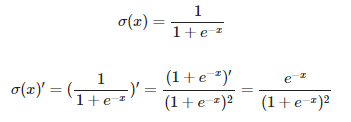

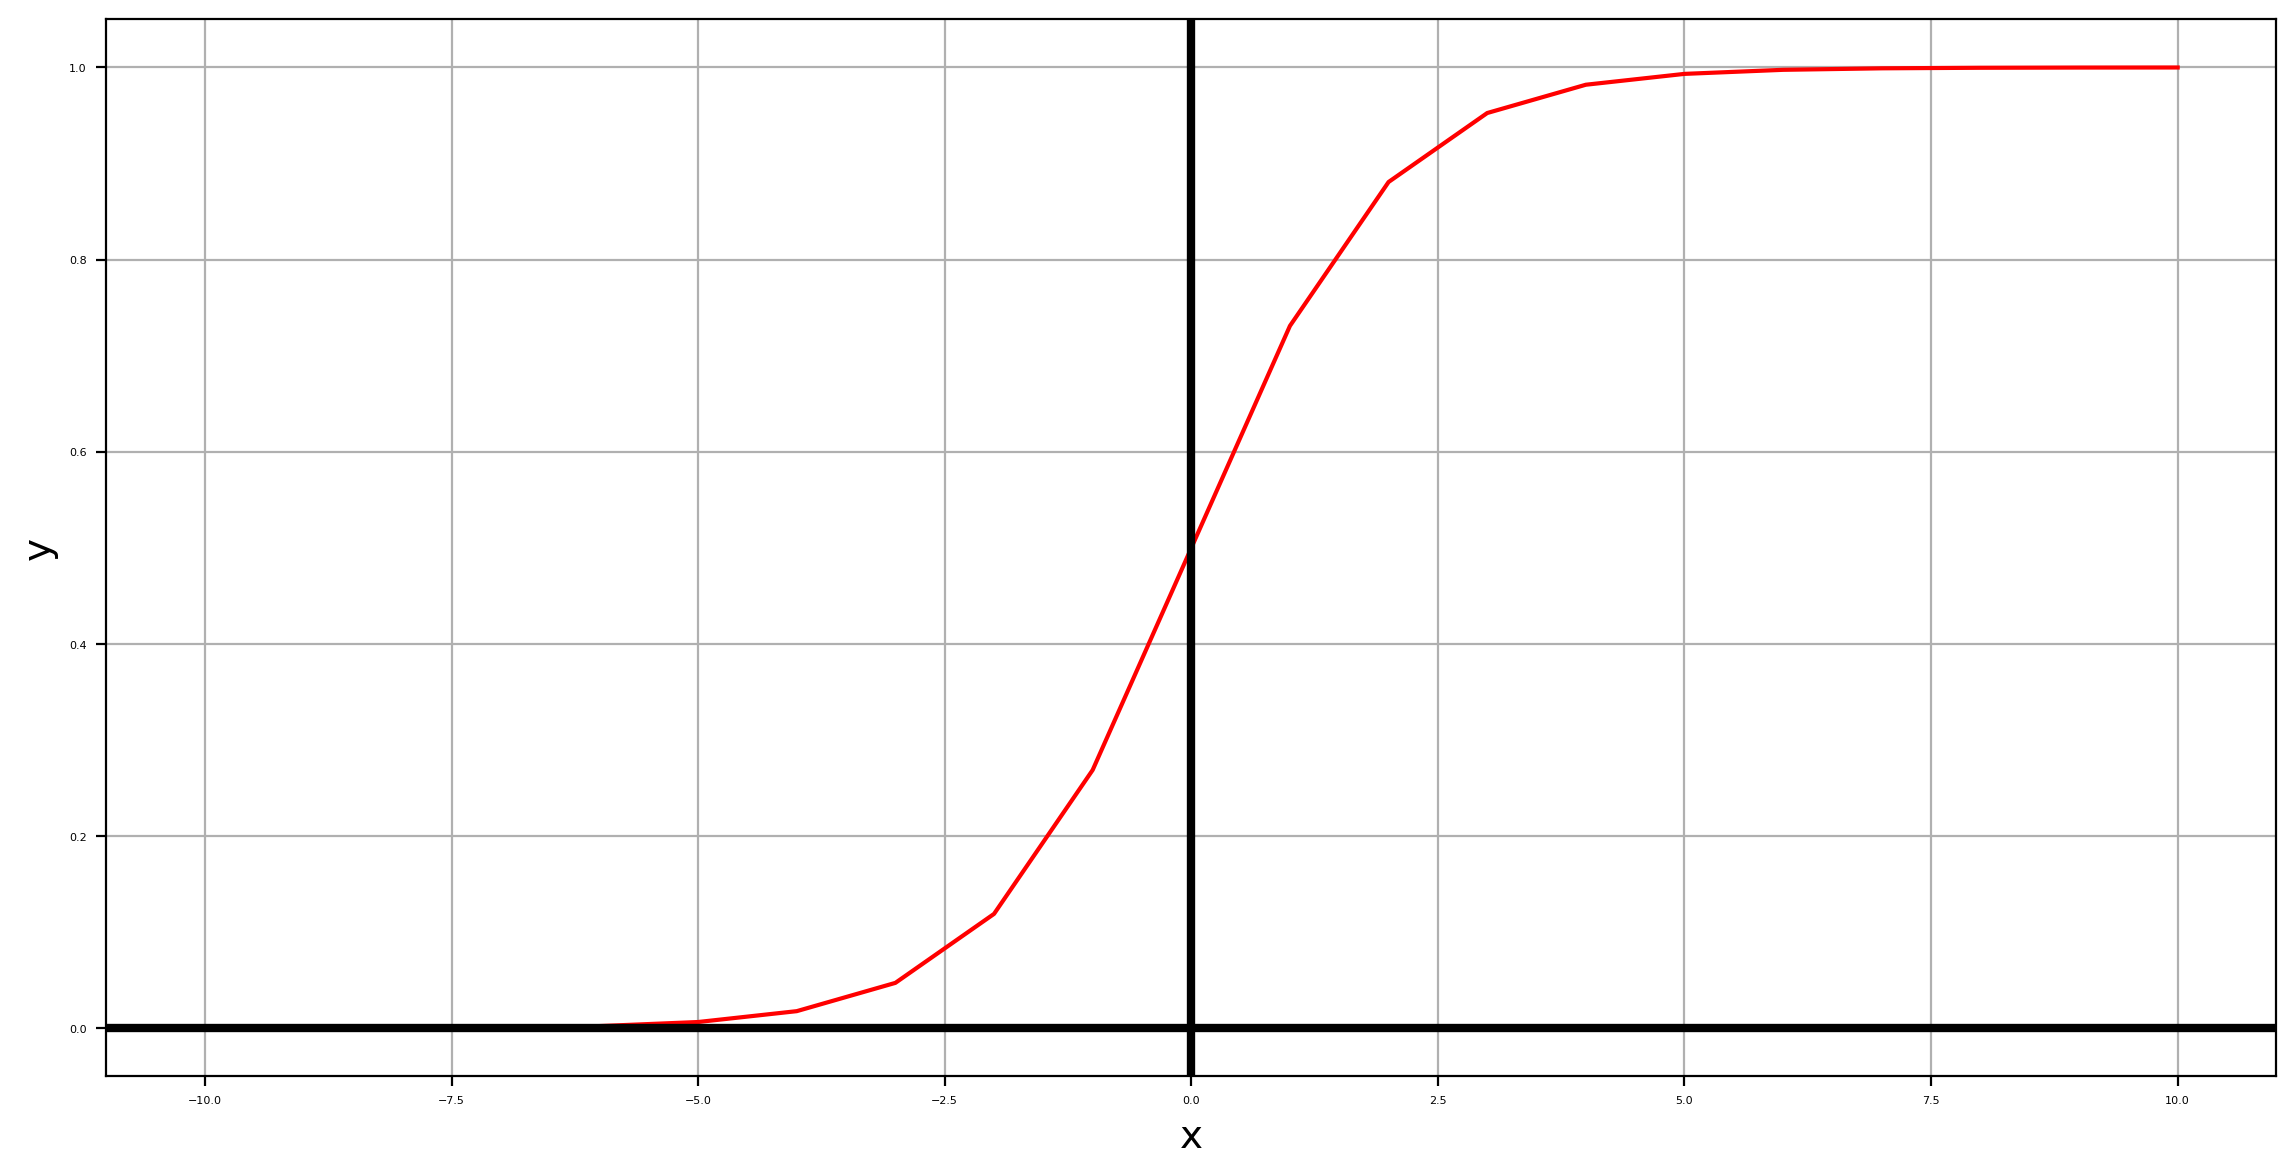

In [15]:
f = lambda x: 1/(1+np.exp(-1*x))
df = lambda x: (np.exp(-x))/(1+np.exp(-x)**2)
x = np.arange(-10,11)

def get_plot(x, f):
    fig = plt.figure(figsize=(14, 7))
    axes = fig.subplots()
    axes.plot(x, f(x), color='red')
    axes.set_xlabel('x', fontsize=14)
    axes.set_ylabel('y', fontsize=14)
    axes.grid(True)
    axes.axhline(y=0, color='black', linewidth=3)
    axes.axvline(x=0, color='black', linewidth=3)

    return axes

axes = get_plot(x, f) 

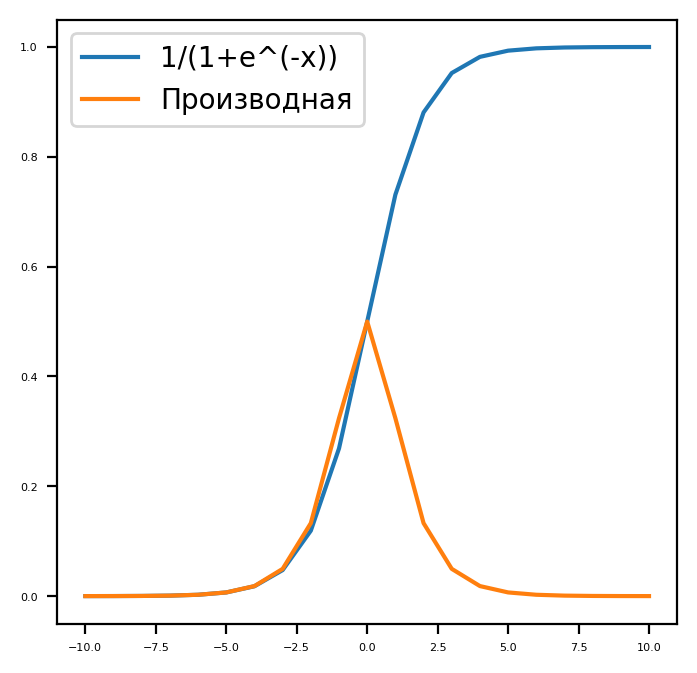

In [16]:
plt.plot(x, f(x), label="1/(1+e^(-x))")
plt.plot(x, df(x), label ="Производная")
plt.legend()

-4.625069167976753

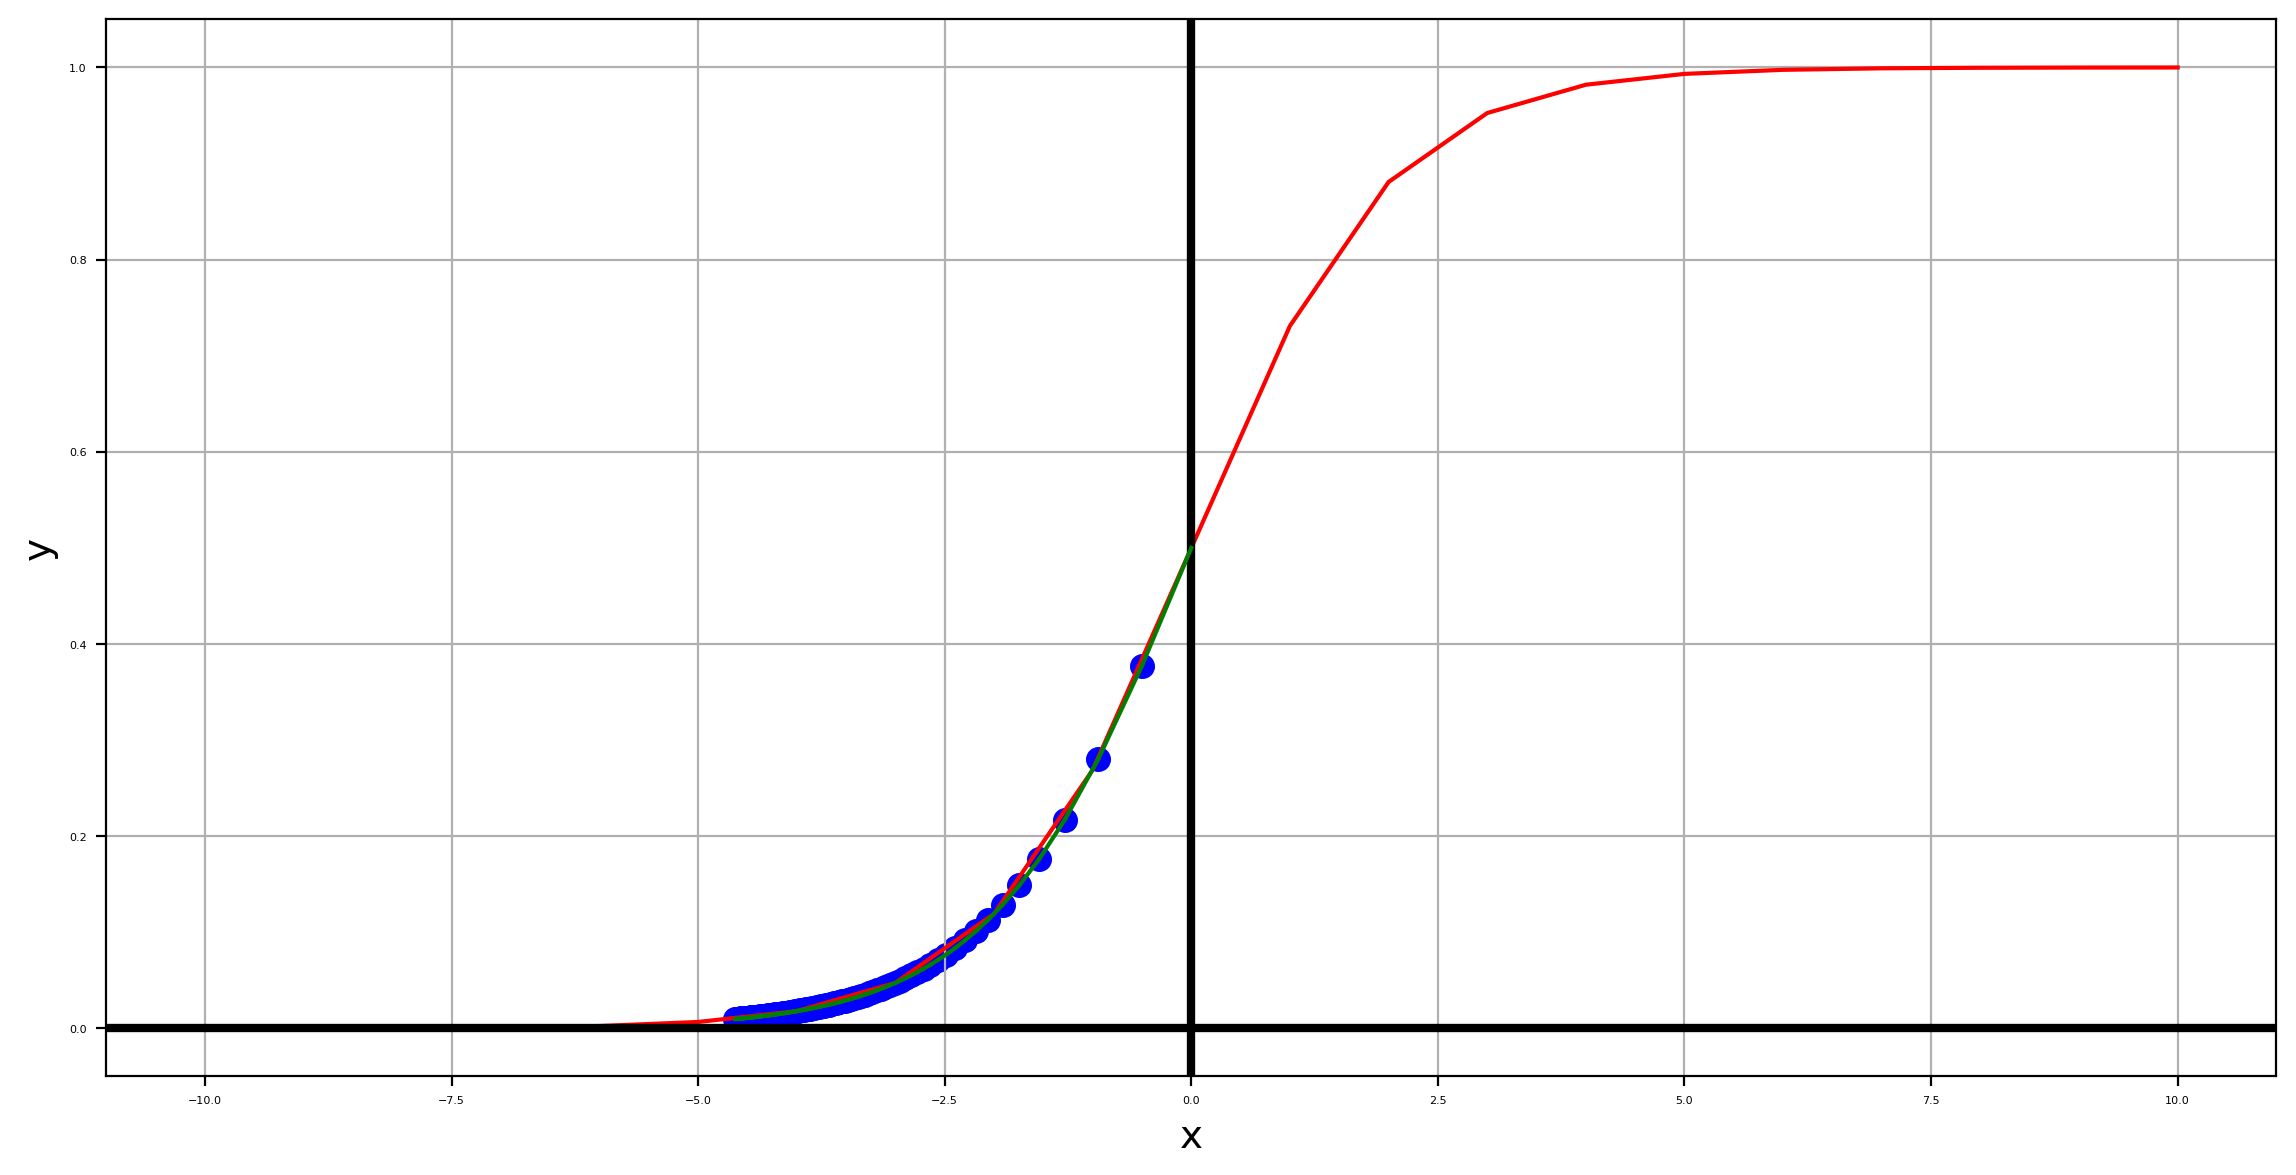

In [17]:
def gradient_descent_to_min(x0=0, sigma=1, f=lambda x : x, df=lambda x: 1, iters=10, axes=None):
    x = x0
    for i in range(iters):
        x0 -= sigma * df(x0)
        if axes:        
            axes.scatter([x0], [f(x0)], color='blue', linewidths=3)        
            axes.plot([x, x0], [f(x), f(x0)], color='green')     
        x = x0 

    return x0  

axes = get_plot(x, f)
gradient_descent_to_min(x0=0, sigma=1, f=f, df=df, iters=100, axes=axes)

Есть только локальный минимум, который находится в левой точке промежутка



### Задание 2

Напишите формулу и код для градиентного спуска для функции
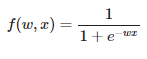

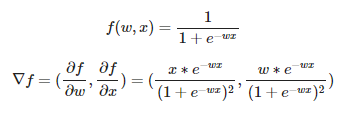

In [18]:
global_epsilon = 0.000000001 
radius = 8
centre = (global_epsilon, global_epsilon)   
arr_shape = 100                             
step = radius / arr_shape

def rotate_vector(length, a):
    return length * np.cos(a), length * np.sin(a)

def differentiable_function(w,x):
    return 1/(1+np.exp(-1*w*x))

def derivative_x(epsilon, arg):
    return (arg*np.exp(-1*arg*epsilon))/((1+np.exp(-1*arg*epsilon))**2)

def derivative_w(epsilon, arg):
    return (arg*np.exp(-1*epsilon*arg))/((1+np.exp(-1*epsilon*arg))**2)

def calculate_flip_points():
    flip_points = np.array([0, 0])
    points = np.zeros((360, arr_shape), dtype=bool)
    cw, cx = centre

    for i in range(arr_shape):
        for alpha in range(360):
            w, x = rotate_vector(step, alpha)
            w = w * i + cw
            x = x * i + cx
            points[alpha][i] = derivative_w(w, x) + derivative_x(x, w) > 0
            if not points[alpha][i - 1] and points[alpha][i]:
                flip_points = np.vstack((flip_points, np.array([alpha, i - 1])))

    return flip_points

def pick_estimates(positions):
    vw, vx = rotate_vector(step, positions[1][0])
    cw, cx = centre
    best_w, best_x = cw + vw * positions[1][1], cx + vx * positions[1][1]

    for index in range(2, len(positions)):
        vw, vx = rotate_vector(step, positions[index][0])
        w, x = cw + vw * positions[index][1], cx + vx * positions[index][1]
        if differentiable_function(best_w, best_x) > differentiable_function(w, x):
            best_w = w
            best_x = x

    for index in range(360):
        vw, vx = rotate_vector(step, index)
        w, x = cw + vw * (arr_shape - 1), cx + vx * (arr_shape - 1)
        if differentiable_function(best_w, best_x) > differentiable_function(w, x):
            best_w = w
            best_x = x

    return best_w, best_x

#градиентный спуск
def gradient_descent(best_estimates, is_w):
    derivative = derivative_w if is_w else derivative_x
    best_w, best_x = best_estimates
    descent_step = step
    value = derivative(best_x, best_w)

    while abs(value) > global_epsilon:
        descent_step *= 0.95
        best_x = best_x - descent_step \
            if derivative(best_x, best_w) > 0 else best_x + descent_step
        value = derivative(best_x, best_w)

    return best_x, best_w

def find_minimum():
    return gradient_descent(gradient_descent(pick_estimates(calculate_flip_points()), False), True)

def get_grid(grid_step):
    samples = np.arange(-radius, radius, grid_step)
    w, x = np.meshgrid(samples, samples)
    
    return w, x, differentiable_function(w, x)

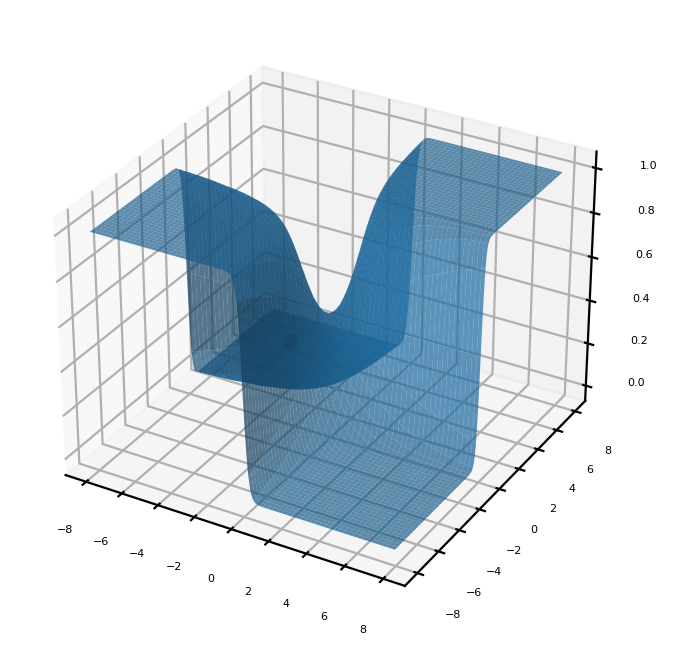

In [19]:
#график
def draw_chart(point, grid):
    point_x, point_y, point_z = point
    grid_x, grid_y, grid_z = grid
    plt.rcParams.update({
        'figure.figsize': (4, 4),
        'figure.dpi': 200,
        'xtick.labelsize': 4,
        'ytick.labelsize': 4
    })
    ax = plt.figure().add_subplot(111, projection='3d')
    ax.scatter(point_x, point_y, point_z, color='red')
    ax.plot_surface(grid_x, grid_y, grid_z, rstride=5, cstride=5, alpha=0.7)
    
    plt.show()
    
min_w, min_x = find_minimum()
minimum = (min_w, min_x, differentiable_function(min_w, min_x))

draw_chart(minimum, get_grid(0.05))

### Задание 3

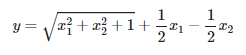

Градиентный спуск с постоянным шагом выполнил 46 шагов
Точка с координатами х1 = -0.617931666157292, x2 = 0.675649030884356


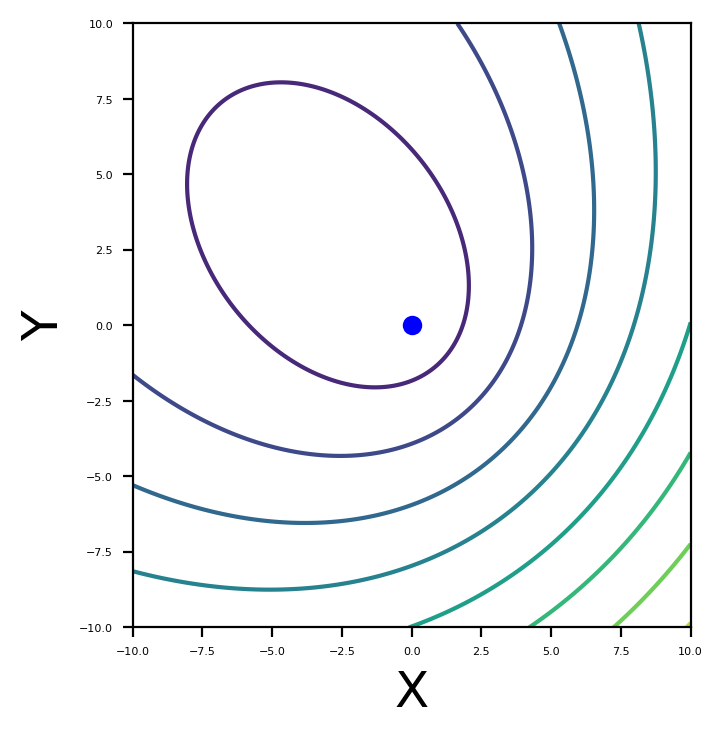

In [25]:
interval = 0;
xx = 0;
yy = 0;

def f(x):
    return (x[0]**2+x[1]**2+1)**(1/2)+(1/2)*x[0]-(1/2)*x[1]
    
def grad_f(x):
    return np.array([x[0]/(x[0]**2+x[1]**2+1)**(1/2)+(1/2), x[1]/(x[0]**2+x[1]**2+1)**(1/2)-(1/2)])


def grad_descent_const_step(x = np.array([1, 1]), alpha = 0.001, epsilon = 0.05):
    grad = grad_f(x)
    n = 0
    check = 0
    while (np.linalg.norm(grad) > epsilon) or (check < 3):
        x = x - alpha*grad
        grad = grad_f(x)
        n+=1
        if (np.linalg.norm(grad) <= epsilon): check +=1
    print("Градиентный спуск с постоянным шагом выполнил {} шагов".format(n))
    print("Точка с координатами х1 = {}, x2 = {}".format(x[0], x[1]))
    interval = n
    xx = x[0]
    yy = x[1]
    return x

x = grad_descent_const_step(alpha = 0.1)

STEP_COUNT = interval
STEP_SIZE = 0.005  # Скорость обучения
X = np.array([i for i in np.linspace(-10, 10, 1000)])
Y = np.array([i for i in np.linspace(-10, 10, 1000)])


def func(X, Y):
    return (X**2+Y**2+1)**(1/2)+(1/2)*X-(1/2)*Y


def dx(x):
    return x/(x**2+y**2+1)**(1/2)+(1/2)


def dy(y):
    return y/(x**2+y**2+1)**(1/2)-(1/2)

skip_first = True
def draw_gradient_points(num, point, line):
    global previous_x, previous_y, skip_first, ax
    if skip_first:
        skip_first = False
        return point
    current_x = previous_x - STEP_SIZE * dx(previous_x)
    current_y = previous_y - STEP_SIZE * dy(previous_y)
    print("Step:", num, "CurX:", current_x, "CurY", current_y, "Fun:", func(current_x, current_y))
    point.set_data([current_x], [current_y])
    # Blah-blah
    new_x = list(line.get_xdata()) + [previous_x, current_x]
    new_y = list(line.get_ydata()) + [previous_y, current_y]
    line.set_xdata(new_x)
    line.set_ydata(new_y)

    previous_x = current_x
    previous_y = current_y
    return point


previous_x, previous_y = 8.8, 8.5
fig, ax = plt.subplots()
p = ax.get_position()
ax.set_position([p.x0 + 0.1, p.y0, p.width * 0.9, p.height])
ax.set_xlabel("X", fontsize=18)
ax.set_ylabel("Y", fontsize=18)

X, Y = np.meshgrid(X, Y)
plt.contour(X, Y, func(X, Y))
point, = plt.plot([xx], [yy], 'bo')
line, = plt.plot([], color='black')